# Simple and Multiple Linear Regression

In this notebook, we will create a small, reproducible dataset and use **scikit-learn** to compare two ways of predicting a continuous value. We will train and evaluate both models on the same training and test split, then visualize a few test predictions and their residuals.

Run the cells from top to bottom. The data file is generated by this notebook, so no separate dataset is needed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 1. Create a reproducible synthetic dataset

We will generate **5,000 observations**. Each row represents one student. The four numerical features are study hours, completed practice tests, attendance rate, and nightly sleep hours. The continuous target, `exam_score`, is based on a linear formula plus random noise. Because the target depends on the features, a linear regression model can learn a meaningful relationship.

A fixed random seed makes the generated data repeatable. The feature ranges below are chosen to be plausible for this example; the target is a synthetic score and is not constrained to a particular scale.

In [2]:
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
number_of_observations = 5_000

hours_studied = rng.uniform(0, 10, number_of_observations)
practice_tests = rng.integers(0, 9, number_of_observations)
attendance_rate = rng.uniform(0.65, 1.0, number_of_observations)
sleep_hours = rng.uniform(4, 10, number_of_observations)
noise = rng.normal(0, 5, number_of_observations)

# The target is a linear combination of the features plus random noise.
exam_score = (
    20
    + 5 * hours_studied
    + 2.5 * practice_tests
    + 20 * attendance_rate
    + 1.5 * sleep_hours
    + noise
)

generated_data = pd.DataFrame(
    {
        "hours_studied": hours_studied,
        "practice_tests": practice_tests,
        "attendance_rate": attendance_rate,
        "sleep_hours": sleep_hours,
        "exam_score": exam_score,
    }
)

csv_path = Path.cwd() / "regression_data.csv"
generated_data.to_csv(csv_path, index=False)
print(f"Saved {len(generated_data):,} observations to {csv_path}")

Saved 5,000 observations to c:\Users\User\Desktop\Emmaunel_AI\etornam_quiz_2\regression_data.csv


## 2. Load and preview the data

Read the CSV back into a pandas DataFrame. The shape is shown as `(rows, columns)`, and `head()` displays the first five observations.

In [3]:
data = pd.read_csv(csv_path)
print(f"DataFrame shape (rows, columns): {data.shape}")
data.head()

DataFrame shape (rows, columns): (5000, 5)


,hours_studied,practice_tests,attendance_rate,sleep_hours,exam_score
0,7.739560,3,0.825539,8.416659,100.435522
1,4.388784,1,0.906338,4.482155,65.361604
2,8.585979,4,0.715879,5.456282,88.243449
3,6.973680,5,0.805327,9.315372,102.930464
4,0.941773,2,0.836386,7.461525,62.152702


## 3. Choose features and split the data

**Simple Linear Regression (SLR)** uses one input feature to predict the target. Here, it uses only `hours_studied`. **Multiple Linear Regression (MLR)** uses two or more input features; here, it uses all four numerical features. Both models predict the same target, `exam_score`.

We reserve 20% of the observations for testing and use the remaining 80% for training. The fixed split seed makes this division repeatable. The models will be fit using training data only.

In [4]:
target = data["exam_score"]
slr_features = data[["hours_studied"]]
mlr_features = data[["hours_studied", "practice_tests", "attendance_rate", "sleep_hours"]]

X_slr_train, X_slr_test, y_train, y_test = train_test_split(
    slr_features, target, test_size=0.2, random_state=RANDOM_SEED
)
X_mlr_train, X_mlr_test, _, _ = train_test_split(
    mlr_features, target, test_size=0.2, random_state=RANDOM_SEED
)

print(f"Training observations: {len(y_train):,}")
print(f"Test observations: {len(y_test):,}")

Training observations: 4,000
Test observations: 1,000


## 4. Train the models and predict

Each `LinearRegression` model is fit on its training features and the training target. We then use each fitted model to predict scores for the same held-out test observations.

In [5]:
slr_model = LinearRegression()
slr_model.fit(X_slr_train, y_train)
slr_predictions = slr_model.predict(X_slr_test)

mlr_model = LinearRegression()
mlr_model.fit(X_mlr_train, y_train)
mlr_predictions = mlr_model.predict(X_mlr_test)

print("Both models have been trained and have made test-set predictions.")

Both models have been trained and have made test-set predictions.


## 5. Evaluate model performance

- **Mean Squared Error (MSE):** the average of squared prediction errors. Squaring gives larger errors more weight, so lower is better.
- **Mean Absolute Error (MAE):** the average absolute prediction error, in the same units as the target. It is the typical size of an error without regard to its direction; lower is better.
- **R² score:** how much of the target's variation the model explains relative to predicting the test-set mean. A value closer to 1 indicates a better fit; 0 is comparable to that baseline, and a negative test score means the model performs worse than that baseline.

We calculate all three metrics on the held-out test set, which was not used to fit either model.

In [6]:
metrics = pd.DataFrame(
    {
        "MSE": [
            mean_squared_error(y_test, slr_predictions),
            mean_squared_error(y_test, mlr_predictions),
        ],
        "MAE": [
            mean_absolute_error(y_test, slr_predictions),
            mean_absolute_error(y_test, mlr_predictions),
        ],
        "R²": [
            r2_score(y_test, slr_predictions),
            r2_score(y_test, mlr_predictions),
        ],
    },
    index=["Simple Linear Regression", "Multiple Linear Regression"],
)
metrics

,MSE,MAE,R²
Simple Linear Regression,78.976693,7.132906,0.723135
Multiple Linear Regression,24.473015,3.945896,0.914206


## 6. Compare actual and predicted values for 10 test observations

The next two plots use the same first 10 rows of the test set. Points show actual and predicted scores. A line connects each pair, and its annotation gives the residual calculated as `actual - predicted`.

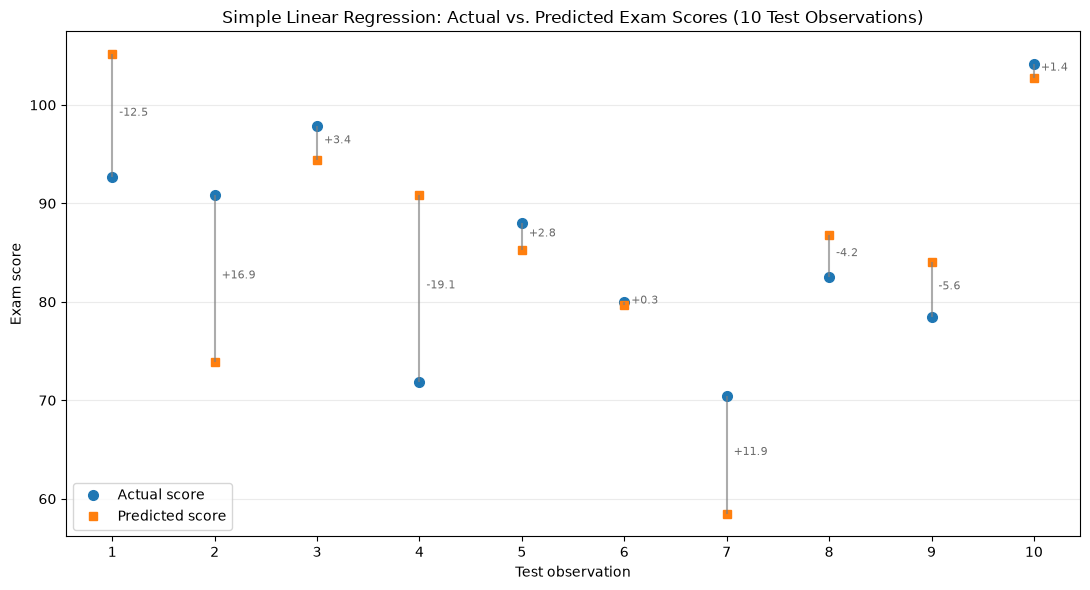

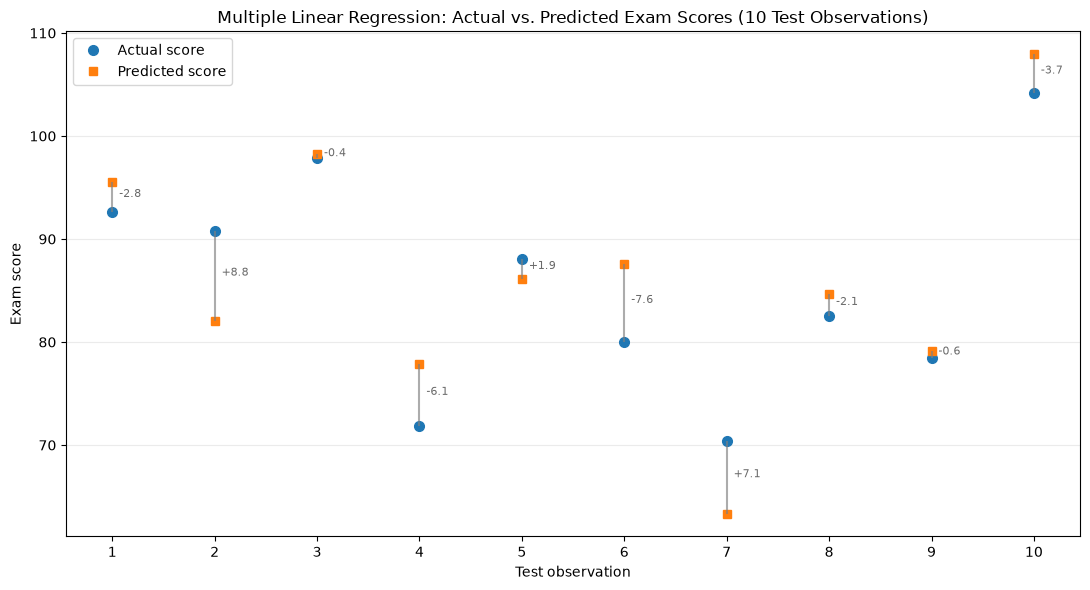

In [7]:
number_to_plot = 10
actual_10 = y_test.iloc[:number_to_plot].to_numpy()
slr_predicted_10 = slr_predictions[:number_to_plot]
mlr_predicted_10 = mlr_predictions[:number_to_plot]
observation_numbers = np.arange(1, number_to_plot + 1)

def plot_actual_vs_predicted(actual, predicted, model_name):
    residuals = actual - predicted
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(
        observation_numbers,
        actual,
        "o",
        label="Actual score",
        markersize=7,
    )
    ax.plot(
        observation_numbers,
        predicted,
        "s",
        label="Predicted score",
        markersize=6,
    )

    for x, actual_value, predicted_value, residual in zip(
        observation_numbers, actual, predicted, residuals
    ):
        ax.vlines(x, predicted_value, actual_value, color="gray", alpha=0.65)
        midpoint = (actual_value + predicted_value) / 2
        ax.annotate(
            f"{residual:+.1f}",
            (x, midpoint),
            xytext=(5, 0),
            textcoords="offset points",
            fontsize=8,
            color="dimgray",
        )

    ax.set_title(f"{model_name}: Actual vs. Predicted Exam Scores (10 Test Observations)")
    ax.set_xlabel("Test observation")
    ax.set_ylabel("Exam score")
    ax.set_xticks(observation_numbers)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

plot_actual_vs_predicted(
    actual_10, slr_predicted_10, "Simple Linear Regression"
)
plot_actual_vs_predicted(
    actual_10, mlr_predicted_10, "Multiple Linear Regression"
)

## 7. Interpret the plots and residuals

A **residual** is `actual - predicted`. A **positive** residual means the actual score is higher than the prediction, so the model underpredicted. A **negative** residual means the prediction was higher than the actual score, so the model overpredicted. The residual's absolute size indicates how far the prediction was from the actual value; a longer connecting line represents a larger error.

The annotations show signed residuals for these 10 examples only. The metrics above summarize performance across the **entire test set**, so use them when comparing overall model performance. Since the synthetic target uses all four features, the MLR model can learn more of the constructed relationship than the SLR model, which sees only study hours.